# Unit 8 – Word2Vec Worked Example (NumPy implementation)
**Module:** Intelligent Agents (IA_PCOM7E, July 2026) · **Student:** Adil Aljasmi

**Seminar task (Unit 8):** *investigate a demonstration of Word2Vec in action with a simple worked example, using Python.*

**Approach.** Instead of calling a library, I implemented Word2Vec's **skip-gram with negative sampling** in NumPy. Skip-gram learns a vector for each word by predicting the words around it (Mikolov et al., 2013a). Negative sampling turns this into a simple yes/no task: is this word really a neighbour, or a randomly drawn "noise" word? Noise words are sampled in proportion to their frequency raised to the power 0.75 (Mikolov et al., 2013b). Writing it by hand shows exactly what the model learns and why.

**Data.** A small, **synthetic** corpus that I generate below from sentence templates about three topics (animals, fruit and vehicles). It is not real text, so results show the mechanism rather than real-world word meanings. Nothing is downloaded.

**Plan:** 1) build the corpus, 2) train the model, 3) check whether words from the same topic end up close together, 4) experiments (context window, vector size, an ambiguous word, training length), 5) findings.

In [1]:
import numpy as np, random
from collections import Counter
import matplotlib.pyplot as plt

SEED = 42
TOPICS = {
    "animal":  ["dog", "cat", "horse", "cow"],
    "fruit":   ["apple", "banana", "mango", "grape"],
    "vehicle": ["car", "bus", "truck", "train"],
}
TEMPLATES = {
    "animal":  ["the {w} runs in the field", "the {w} sleeps in the barn", "a hungry {w} eats grass", "the farmer feeds the {w}"],
    "fruit":   ["she ate a ripe {w}", "the {w} is sweet and juicy", "we picked a {w} from the tree", "a fresh {w} in the bowl"],
    "vehicle": ["he drove the {w} to town", "the {w} stopped at the station", "a fast {w} on the road", "the {w} needs more fuel"],
}

def make_corpus(n_sentences=900, seed=SEED, extra=None):
    """Random sentences from the templates. `extra` adds (word, [topics]) pairs used in several topics."""
    rng = random.Random(seed)
    words = {t: list(ws) for t, ws in TOPICS.items()}
    if extra:
        for w, ts in extra:
            for t in ts:
                words[t].append(w)
    out = []
    for _ in range(n_sentences):
        t = rng.choice(list(TEMPLATES))
        out.append(rng.choice(TEMPLATES[t]).format(w=rng.choice(words[t])).split())
    return out

corpus = make_corpus()
counts = Counter(w for s in corpus for w in s)
print(f"{len(corpus)} sentences, {sum(counts.values())} tokens, {len(counts)} distinct words")
print("example:", " | ".join(" ".join(s) for s in corpus[:3]))

900 sentences, 5156 tokens, 50 distinct words
example: he drove the car to town | a fast bus on the road | the dog sleeps in the barn


average loss per training pair: first epoch 2.804 -> last epoch 1.394


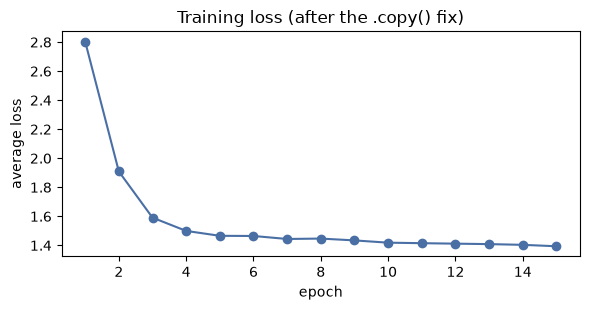

In [2]:
class SkipGramNS:
    """Skip-gram with negative sampling (Mikolov et al., 2013a; 2013b), plain NumPy, plain SGD."""
    def __init__(self, corpus, dim=20, window=2, negatives=5, subsample=None, seed=SEED):
        self.corpus, self.window, self.k, self.t = corpus, window, negatives, subsample
        self.vocab = sorted({w for s in corpus for w in s})
        self.ix = {w: i for i, w in enumerate(self.vocab)}
        self.rng = np.random.default_rng(seed)
        V = len(self.vocab)
        self.W_in = (self.rng.random((V, dim)) - 0.5) / dim     # word vectors (what we keep)
        self.W_out = np.zeros((V, dim))                          # context vectors
        self.cnt = Counter(w for s in corpus for w in s); self.total = sum(self.cnt.values())
        freq = np.array([self.cnt[v] for v in self.vocab], float)
        self.noise = freq ** 0.75 / (freq ** 0.75).sum()         # unigram^0.75 noise distribution

    def _pairs(self):
        sents = self.corpus
        if self.t:   # frequent-word subsampling (Mikolov et al., 2013b): keep w with prob sqrt(t / f(w))
            keep = lambda w: self.rng.random() < min(1.0, np.sqrt(self.t / (self.cnt[w] / self.total)))
            sents = [[w for w in s if keep(w)] for s in sents]
        win = self.window
        return np.array([(self.ix[s[i]], self.ix[s[j]]) for s in sents for i in range(len(s))
                         for j in range(max(0, i - win), min(len(s), i + win + 1)) if j != i])

    def train(self, epochs=15, lr=0.025):
        sig = lambda x: 1 / (1 + np.exp(-np.clip(x, -30, 30)))   # clip: avoids exp overflow warnings
        losses = []
        for ep in range(epochs):
            pairs = self._pairs()
            a = lr * (1 - ep / epochs) + 1e-4                     # linearly decaying learning rate
            order = self.rng.permutation(len(pairs))
            negs = self.rng.choice(len(self.vocab), size=(len(order), self.k), p=self.noise)
            total = 0.0
            for n, (c, o) in enumerate(pairs[order]):
                # FIX (remediation): .copy() is essential. A plain W_in[c] is a NumPy *view*, so the
                # in-place update below silently changed v before W_out used it; training diverged
                # (loss rose from 2.5 to 21 in my first run).
                v = self.W_in[c].copy()
                neg = negs[n][negs[n] != o]                       # a noise word must not be the true context
                ids = np.concatenate(([o], neg))
                labels = np.zeros(len(ids)); labels[0] = 1       # 1 = real neighbour, 0 = noise
                u = self.W_out[ids]
                p = sig(u @ v)
                g = p - labels                                    # gradient of the logistic loss
                self.W_in[c] -= a * (g @ u)
                self.W_out[ids] -= a * np.outer(g, v)
                total += -np.log(p[0] + 1e-9) - np.log(1 - p[1:] + 1e-9).sum()
            losses.append(total / len(order))
        return losses

    def vec(self, w):
        x = self.W_in[self.ix[w]]
        return x / np.linalg.norm(x)

    def similar(self, w, topn=4):
        sims = {v: float(self.vec(w) @ self.vec(v)) for v in self.vocab if v != w}
        return sorted(sims.items(), key=lambda kv: -kv[1])[:topn]

model = SkipGramNS(corpus)
losses = model.train()
print("average loss per training pair: first epoch %.3f -> last epoch %.3f" % (losses[0], losses[-1]))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(1, len(losses) + 1), losses, "o-", color="#4a6fa5")
ax.set_xlabel("epoch"); ax.set_ylabel("average loss"); ax.set_title("Training loss (after the .copy() fix)")
fig.tight_layout(); fig.savefig("8.Unit08 Word2Vec training loss.png", dpi=150); plt.show()

In [3]:
TOPIC_WORDS = [w for ws in TOPICS.values() for w in ws]
topic_of = {w: t for t, ws in TOPICS.items() for w in ws}

def evaluate(m):
    """Neighbour accuracy: share of topic words whose nearest topic word is from the same topic.
    Also mean cosine similarity within vs between topics."""
    hits, within, between = 0, [], []
    for w in TOPIC_WORDS:
        others = [(v, float(m.vec(w) @ m.vec(v))) for v in TOPIC_WORDS if v != w]
        best = max(others, key=lambda x: x[1])[0]
        hits += topic_of[best] == topic_of[w]
        for v, s in others:
            (within if topic_of[v] == topic_of[w] else between).append(s)
    return hits / len(TOPIC_WORDS), np.mean(within), np.mean(between)

acc, w_in, w_out = evaluate(model)
print(f"nearest-neighbour topic accuracy: {acc:.2f}")
print(f"mean cosine within topic: {w_in:.3f}   between topics: {w_out:.3f}")
for w in ["dog", "apple", "train", "barn"]:
    print(f"{w:>6} ->", ", ".join(f"{v} ({s:.2f})" for v, s in model.similar(w)))

nearest-neighbour topic accuracy: 1.00
mean cosine within topic: 0.996   between topics: 0.628
   dog -> horse (1.00), cow (1.00), cat (1.00), farmer (0.87)
 apple -> mango (1.00), grape (1.00), banana (0.99), we (0.87)
 train -> car (1.00), truck (0.99), bus (0.99), fuel (0.84)
  barn -> bowl (1.00), field (1.00), runs (0.91), sleeps (0.91)


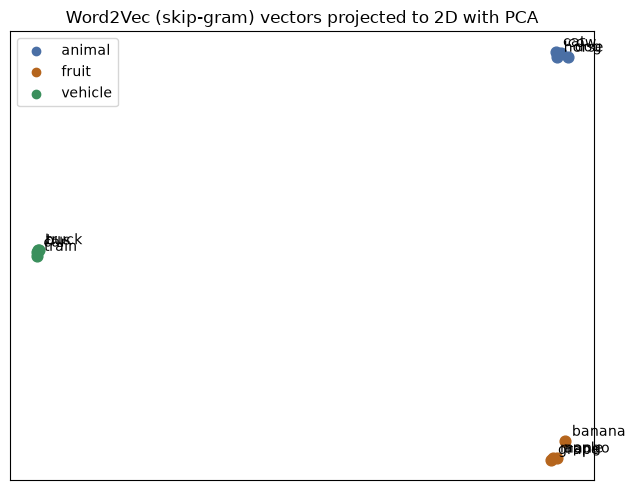

In [4]:
def plot_2d(m, words, title, path):
    X = np.array([m.vec(w) for w in words])
    X = X - X.mean(0)
    _, _, Vt = np.linalg.svd(X, full_matrices=False)             # PCA via SVD, no extra libraries
    P = X @ Vt[:2].T
    colours = {"animal": "#4a6fa5", "fruit": "#b5651d", "vehicle": "#3a8f5c"}
    fig, ax = plt.subplots(figsize=(6.5, 5))
    for (x, y), w in zip(P, words):
        ax.scatter(x, y, color=colours.get(topic_of.get(w), "#999"), s=60)
        ax.annotate(w, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=10)
    for t, c in colours.items():
        ax.scatter([], [], color=c, label=t)
    ax.legend(); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

plot_2d(model, TOPIC_WORDS, "Word2Vec (skip-gram) vectors projected to 2D with PCA",
        "8.Unit08 Word2Vec embeddings PCA.png")

## Experiments
Each experiment changes one setting and re-trains on the same corpus, then reports neighbour accuracy and the gap between within-topic and between-topic similarity (a bigger gap means clearer separation).

In [5]:
def run(**kw):
    epochs = kw.pop("epochs", 15)
    m = SkipGramNS(corpus, **kw); m.train(epochs=epochs)
    acc, wi, wo = evaluate(m)
    return acc, wi - wo

print("E1 context window (dim=20)")
for win in (1, 2, 4):
    acc, gap = run(window=win)
    print(f"   window={win}: accuracy {acc:.2f}, within-between gap {gap:.3f}")

print("E2 vector size (window=2)")
for d in (2, 5, 20, 50):
    acc, gap = run(dim=d)
    print(f"   dim={d:>2}: accuracy {acc:.2f}, within-between gap {gap:.3f}")

print("E3 training length (window=2, dim=20)")
for ep in (1, 3, 15):
    acc, gap = run(epochs=ep)
    print(f"   epochs={ep:>2}: accuracy {acc:.2f}, within-between gap {gap:.3f}")

print("E4 frequent-word subsampling (Mikolov et al., 2013b); t is high because the corpus is tiny")
for t in (None, 1e-2):
    acc, gap = run(subsample=t)
    print(f"   subsample t={t}: accuracy {acc:.2f}, within-between gap {gap:.3f}")

E1 context window (dim=20)


   window=1: accuracy 1.00, within-between gap 0.467


   window=2: accuracy 1.00, within-between gap 0.369


   window=4: accuracy 1.00, within-between gap 0.361
E2 vector size (window=2)


   dim= 2: accuracy 1.00, within-between gap 0.137


...

   epochs= 1: accuracy 1.00, within-between gap 0.085


   epochs= 3: accuracy 1.00, within-between gap 0.482


   epochs=15: accuracy 1.00, within-between gap 0.369
E4 frequent-word subsampling (Mikolov et al., 2013b); t is high because the corpus is tiny


   subsample t=None: accuracy 1.00, within-between gap 0.369


   subsample t=0.01: accuracy 1.00, within-between gap 0.606


mean similarity of 'jaguar' to animal  : 0.863
mean similarity of 'jaguar' to fruit   : 0.554
mean similarity of 'jaguar' to vehicle : 0.887
nearest neighbours of 'jaguar': bus (0.90), car (0.89), train (0.88), truck (0.88), cat (0.87), cow (0.87)


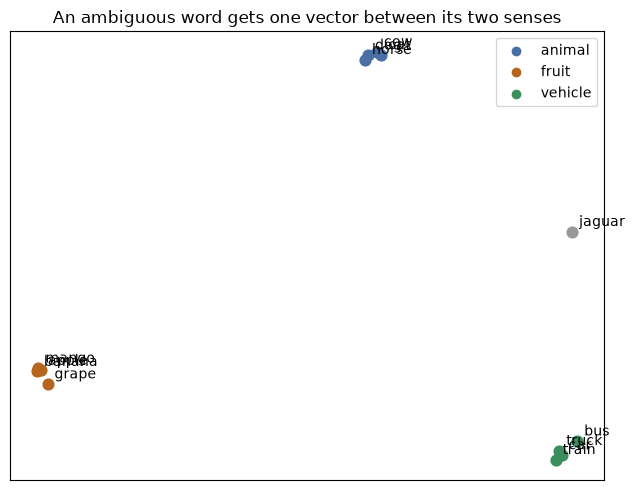

In [6]:
# E5: an ambiguous word. 'jaguar' is used both as an animal and as a vehicle (a car brand).
amb_corpus = make_corpus(extra=[("jaguar", ["animal", "vehicle"])])
amb = SkipGramNS(amb_corpus); amb.train()
mean_sim = lambda w, group: np.mean([amb.vec(w) @ amb.vec(v) for v in group])
for t, ws in TOPICS.items():
    print(f"mean similarity of 'jaguar' to {t:<8}: {mean_sim('jaguar', ws):.3f}")
print("nearest neighbours of 'jaguar':", ", ".join(f"{v} ({s:.2f})" for v, s in amb.similar("jaguar", 6)))
topic_of["jaguar"] = None
plot_2d(amb, TOPIC_WORDS + ["jaguar"], "An ambiguous word gets one vector between its two senses",
        "8.Unit08 Word2Vec ambiguous word.png")

## Findings

**What the model learned.** After 15 epochs the average loss per training pair fell from 2.80 to 1.39. All 12 topic words had a nearest topic word from their own topic (accuracy 1.00). The mean cosine similarity was 0.996 within topics and 0.628 between topics. For example, *dog*'s nearest neighbours were *horse*, *cow* and *cat*, and *train*'s were *car*, *truck* and *bus*. The model was never told the topics: it learned them only from which words appear around which (Mikolov et al., 2013a). The PCA plot shows three separate clusters.

**A useful surprise.** *barn*'s nearest neighbours were *bowl* and *field*, which come from different topics. All three appear in the same slot (*"in the ___"*). Word2Vec measures similarity of **context**, not similarity of meaning, so words that are used the same way end up close together whatever they refer to. The within-topic similarity is also almost 1 because my templates make same-topic words fully interchangeable. Real text is far less regular.

**Experiments.**
- **E1, context window:** accuracy stayed at 1.00. The separation gap was largest with a window of 1 (0.467), compared with 0.369 for 2 and 0.361 for 4. In short templates, a narrow window captures the word's own phrase, while a wider window pulls in shared words such as *the* and *a*.
- **E2, vector size:** even 2 dimensions were enough for 1.00 accuracy, but with a much smaller gap (0.137). From 5 to 50 dimensions the gap was steady at about 0.36&ndash;0.37, so with only 50 words, extra dimensions add nothing.
- **E3, training length:** one epoch already gave 1.00 accuracy, but only a 0.085 gap. Three epochs gave 0.482, and 15 epochs 0.369. Accuracy alone hides how clearly the topics are separated.
- **E4, frequent-word subsampling** (Mikolov et al., 2013b): randomly dropping very frequent words such as *the* raised the gap from 0.369 to 0.606, the clearest separation of any run. I used t = 0.01 rather than the paper's much smaller values because this corpus is tiny.
- **E5, an ambiguous word:** *jaguar* was used both as an animal and as a vehicle. It received **one** vector, with a mean similarity of 0.863 to the animals and 0.887 to the vehicles (0.554 to fruit). Its neighbours mixed *bus*, *car*, *cat* and *cow*. Word2Vec gives one vector per word form, so the two senses are blended. This is the same problem as the ambiguous parse tree in this unit, at the level of word meaning.

**Remediation.** My first run diverged: the loss rose from 2.50 to 21.27 and NumPy reported overflow. The cause was my own bug. `v = W_in[c]` is a NumPy *view*, so updating `W_in[c]` in place silently changed `v` before the context vectors were updated with it. Taking a `.copy()` fixed it; with the original settings and the copy, the loss fell from 2.51 to 1.57. I also stopped noise samples from being the true context word, and clipped the sigmoid input. All results above come from the corrected code.

**Reflection.** Building Word2Vec by hand showed me that embeddings are statistics of usage. They group words that occur in the same contexts, which is powerful but not the same as understanding. The *barn/bowl* and *jaguar* results show the limits: an agent that relies on such vectors inherits the distribution of its training text, including ambiguities and accidental similarities. The divergence bug was also a useful lesson. A falling loss curve is a basic check I should look at before trusting any result, and I saved it as a figure.

## References
Mikolov, T., Chen, K., Corrado, G. & Dean, J. (2013a) Efficient estimation of word representations in vector space. *arXiv preprint* arXiv:1301.3781. Available from: https://arxiv.org/abs/1301.3781 [Accessed 18 October 2026].

Mikolov, T., Sutskever, I., Chen, K., Corrado, G. & Dean, J. (2013b) Distributed representations of words and phrases and their compositionality. *Advances in Neural Information Processing Systems 26 (NIPS 2013)*. Available from: https://arxiv.org/abs/1310.4546 [Accessed 18 October 2026].